In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['font.family'] = 'Sans Serif'
rcParams['font.size'] = 12
rcParams['figure.autolayout'] = True
rcParams["savefig.bbox"] = 'tight'
rcParams["savefig.format"] = 'png'
rcParams["savefig.dpi"] = 300
rcParams["grid.linestyle"] = '--'

In [15]:
import os
import subprocess
import sys
from datetime import datetime, timedelta, timezone
from glob import glob

import h5py
import pandas as pd
import scipy.signal as sgn
import torch

# reuse the filter/plot helpers and DasData from the Neubrex notebook folder
sys.path.insert(0, os.path.abspath("../NbDasPhaseNet"))
import NbDasUtils as utils
from NbDas import DasData

In [16]:
%matplotlib inline

## Read AP Sensing DAS H5 file

AP Sensing files store the samples in the `DAS` dataset (time × distance, int32 scaled differential phase),
with positions in `Distances/MeterPositions` and per-trace timestamps (µs since Unix epoch, UTC) in `Timestamps/DataTimestamps`.

In [17]:
UNIX_EPOCH = datetime(1970, 1, 1, tzinfo=timezone.utc)


def read_scalar(h5_file, path):
    """Read an AP Sensing single-element metadata dataset, decoding byte strings."""
    value = h5_file[path][()].item()
    return value.decode() if isinstance(value, bytes) else value


def read_ap_h5(h5_file):
    """AP Sensing counterpart of utils.read_h5; also returns the UTC time of the first trace."""
    das_dataset = h5_file["DAS"]
    n_time, n_dist = das_dataset.shape
    print("DAS data shape:", das_dataset.shape)

    # Built from begin + step rather than the stored per-sample arrays, which jitter
    # slightly (float32 positions, µs-rounded timestamps).
    positions_attrs = h5_file["Distances/MeterPositions"].attrs
    first_position = float(positions_attrs["BeginPositionInMeters"].item())  # [m]
    spatial_sampling_interval = float(positions_attrs["StepInMeters"].item())  # [m]
    time_sampling_interval = 1.0 / float(das_dataset.attrs["DataRateHz"].item())  # [s]

    first_timestamp_us = int(h5_file["Timestamps/DataTimestamps"][0, 0])
    start_time = UNIX_EPOCH + timedelta(microseconds=first_timestamp_us)

    print(
        f"Start: {start_time.isoformat()}, data rate: {1 / time_sampling_interval:g} Hz, "
        f"spatial sampling: {spatial_sampling_interval:.4g} m, "
        f"gauge length: {read_scalar(h5_file, 'ProcessingServer/GaugeLength'):.4g} m, "
        f"data type: {read_scalar(h5_file, 'ProcessingServer/DataType')}"
    )

    time_series = np.arange(n_time) * time_sampling_interval
    dist_series = first_position + np.arange(n_dist) * spatial_sampling_interval
    return das_dataset, spatial_sampling_interval, time_sampling_interval, time_series, dist_series, start_time

In [28]:
h5_filepath = "D:\\Sample_data\\Earthquake-APSensing-Tokyohashi-Gifu-Shinkansen-20261107/0001437037_2026-11-07_16.03.44.43284_VDS.h5"

print("Reading DAS data from HDF5 file: ", h5_filepath)
with h5py.File(h5_filepath, "r") as h5_file:
    (
        das_dataset,
        spatial_sampling_interval,
        time_sampling_interval,
        time_series,
        dist_series,
        start_time,
    ) = read_ap_h5(h5_file)
    # Scaled phase counts with no factor to physical units in the file. They are used as
    # strain rate: the spectrum does not rise toward low frequencies as strain would, and
    # PhaseNet-DAS normalizes amplitudes, so the unknown scale does not matter.
    das_data = das_dataset[()].astype(np.float32)

# apply highpass filter to remove low frequency noise
print("Applying highpass filter...")
das_data = utils.sos_highpass_filter(das_data, 3, cutf=0.5, fs=1/time_sampling_interval)

# PhaseNet-DAS was trained on 100 Hz data; decimate() applies an anti-aliasing filter first
target_sampling_rate = 100.0  # [Hz]
decimation_factor = round(1 / (time_sampling_interval * target_sampling_rate))
if decimation_factor > 1:
    print(f"Decimating by {decimation_factor} to {target_sampling_rate:g} Hz...")
    das_data = sgn.decimate(das_data, decimation_factor, ftype="fir", axis=0)
    time_series = time_series[::decimation_factor]
    time_sampling_interval *= decimation_factor

# The event energy spans the whole 60 s file, so it is not cropped by default.
# das_data, time_series = utils.crop_das_time_range(das_data, time_series, (10, 40))
# das_data, dist_series = utils.crop_das_distance_range(das_data, dist_series, (0, 30000))

das_data = DasData(das_data, spatial_sampling_interval, time_sampling_interval, dist_series, time_series)
print(f"Preprocessed DAS data shape: {das_data.data.shape}, time interval: {das_data.time_interval:g} s")

Reading DAS data from HDF5 file:  D:\Sample_data\Earthquake-APSensing-Tokyohashi-Gifu-Shinkansen-20261107/0001437037_2026-11-07_16.03.44.43284_VDS.h5
DAS data shape: (24000, 10214)
Start: 2026-11-07T16:03:44.432838+00:00, data rate: 200 Hz, spatial sampling: 9.801 m, gauge length: 19.6 m, data type: SCALED_DIFFERENTIAL_PHASE_32
Applying highpass filter...
Decimating by 2 to 100 Hz...
Preprocessed DAS data shape: (12000, 10214), time interval: 0.01 s


In [29]:
# Save in the Neubrex layout ("Acoustic" dataset, time x distance) so predict.py can read it with --system neubrex.
# The name avoids extra dots, since predict.py derives the pick CSV name from it.
file_id = os.path.basename(h5_filepath).split("_")[0]
begin_time = start_time + timedelta(seconds=float(time_series[0]))
new_file_name = f"AP_{file_id}_{begin_time:%Y%m%dT%H%M%S}_StrainRate_{target_sampling_rate:g}Hz.h5"
output_h5_filepath = "./strainrate/" + new_file_name
print("Saving preprocessed DAS data to HDF5 file: ", output_h5_filepath)

with h5py.File(output_h5_filepath, "w") as new_h5_file:
    dset_write = new_h5_file.create_dataset("Acoustic", data=das_data.data.astype(np.float32))
    dset_write.attrs["SpatialSamplingInterval"] = spatial_sampling_interval
    dset_write.attrs["TimeSamplingInterval(seconds)"] = time_sampling_interval
    dset_write.attrs["ISO8601TimeStamp"] = begin_time.isoformat(timespec="microseconds")
    dset_write.attrs["StartPosition"] = dist_series[0]
    dset_write.attrs["DataType"] = "strain-rate"
    dset_write.attrs["DataPhysicalUnit"] = "scaled differential phase (counts)"
    dset_write.attrs["SourceFile"] = os.path.basename(h5_filepath)

Saving preprocessed DAS data to HDF5 file:  ./strainrate/AP_0001437037_20261107T160344_StrainRate_100Hz.h5


Time downsample factor:  4
Distance downsample factor:  3


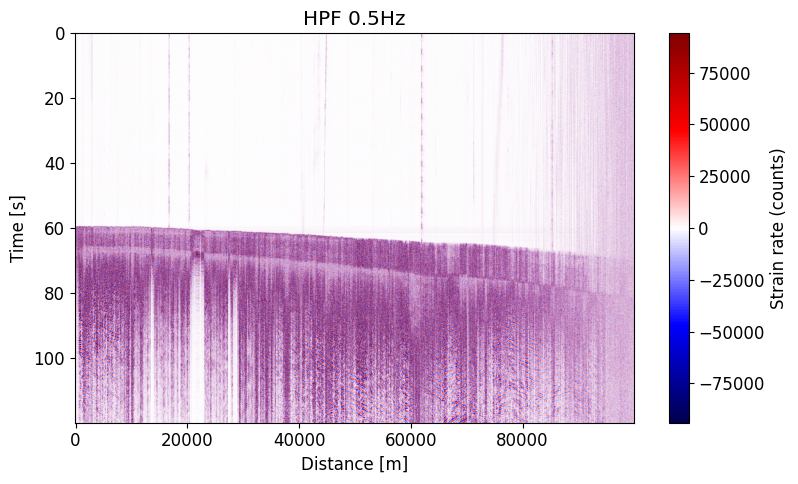

In [30]:
color_limit = np.percentile(np.abs(das_data.data[::10, ::10]), 99)

plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", title="HPF 0.5Hz", vmin=-color_limit, vmax=color_limit)
plt.gcf().axes[-1].set_ylabel("Strain rate (counts)")
plt.grid(False)

## Run PhaseNet-DAS

In [31]:
# Write input file to files.txt
with open("files.txt", "w") as f:
    f.write(f"strainrate/{new_file_name}\n")

In [32]:
ngpu = torch.cuda.device_count()
base_cmd = "../predict.py --model phasenet_das --data_list=files.txt  --data_path ./strainrate --result_path ./results --format=h5  --batch_size 1 --workers 0 --system neubrex"

In [35]:
# sys.executable runs predict.py in this kernel's environment
if ngpu == 0:
    cmd = f'"{sys.executable}" {base_cmd} --device cpu'
elif ngpu == 1:
    cmd = f'"{sys.executable}" {base_cmd}'
else:
    cmd = f"torchrun --nproc_per_node {ngpu} {base_cmd}"

print(cmd)
# captured and printed here because os.system output does not reach the notebook on Windows
result = subprocess.run(cmd, shell=True, capture_output=True, text=True)
print(result.stdout)
print(result.stderr)
result.check_returncode()

"c:\Users\Aung\OneDrive_Neubrex\DAS_Research\PhaseNetDAS\EQNet\.venv\Scripts\python.exe" ../predict.py --model phasenet_das --data_list=files.txt  --data_path ./strainrate --result_path ./results --format=h5  --batch_size 1 --workers 0 --system neubrex --device cpu
Not using distributed mode
Namespace(model='phasenet_das', resume='', backbone='unet', phases=['P', 'S'], device='cpu', workers=0, batch_size=1, use_deterministic_algorithms=False, amp=False, world_size=1, dist_url='env://', data_path='./strainrate', data_list='files.txt', hdf5_file=None, prefix='', format='h5', dataset='das', result_path='./results', plot_figure=False, min_prob=0.3, add_polarity=False, add_event=False, sampling_rate=100.0, highpass_filter=0.0, response_path=None, response_xml=None, subdir_level=0, cut_patch=False, nt=20480, nx=5120, resample_time=False, resample_space=False, system='neubrex', location=None, skip_existing=False, distributed=False)
Total samples: 1 files

c:\Users\Aung\OneDrive_Neubrex\DAS_Re

## Plot results

In [36]:
pick_files = glob(f"results/picks_phasenet_das/{os.path.splitext(new_file_name)[0]}*.csv")
picks = pd.read_csv(pick_files[0])
print(picks["phase_type"].value_counts())
picks.head()

phase_type
P    13198
S     6843
Name: count, dtype: int64


,channel_index,phase_index,phase_time,phase_score,phase_type
0,0,5939,2026-11-07T16:04:43.822+00:00,0.750,P
1,0,6235,2026-11-07T16:04:46.782+00:00,0.371,S
2,1,5939,2026-11-07T16:04:43.822+00:00,0.815,P
3,1,6235,2026-11-07T16:04:46.782+00:00,0.389,S
4,2,5939,2026-11-07T16:04:43.822+00:00,0.864,P


Time downsample factor:  4
Distance downsample factor:  3


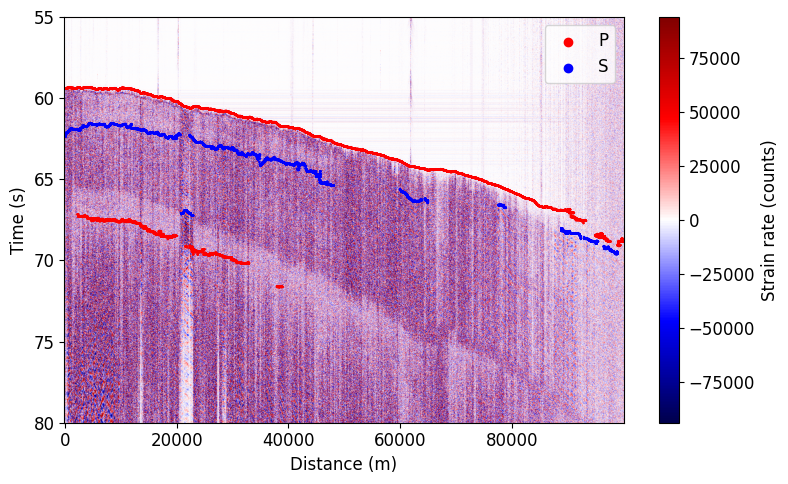

In [39]:
plt.figure(figsize=(8, 5))
das_data.plot_data(cmap="seismic", title="", vmin=-color_limit, vmax=color_limit)
plt.gcf().axes[-1].set_ylabel("Strain rate (counts)")
color = picks["phase_type"].map({"P": "r", "S": "b"})
dx = das_data.spatial_interval
dt = das_data.time_interval
# AP channel 0 is not at 0 m, so offset by the first position
plt.scatter(picks["channel_index"].values * dx + dist_series[0], picks["phase_index"].values * dt + time_series[0], c=color, s=0.5)
plt.scatter([], [], c="r", label="P")
plt.scatter([], [], c="b", label="S")
plt.legend()
plt.xlabel("Distance (m)")
plt.ylabel("Time (s)")
plt.ylim(80, 55)
plt.grid(False)